In [9]:
import os
os.makedirs("/root/.kaggle", exist_ok=True)
!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

In [2]:
!pip install -q kagglehub split-folders

import kagglehub, splitfolders, os

path = kagglehub.dataset_download(
    "belsonraja/face-mask-dataset-with-and-without-mask"
)

input_folder = os.path.join(path, "facemask-dataset", "dataset")

splitfolders.ratio(
    input_folder,
    output="/content/output_dataset",
    seed=42,
    ratio=(0.7, 0.2, 0.1)
)

for split in ["train", "val", "test"]:
    for cls in os.listdir(f"/content/output_dataset/{split}"):
        n = len(os.listdir(f"/content/output_dataset/{split}/{cls}"))
        print(split, cls, n)

Using Colab cache for faster access to the 'face-mask-dataset-with-and-without-mask' dataset.


Copying files: 3833 files [00:35, 108.89 files/s]

train with_mask 1340
train without_mask 1342
val with_mask 383
val without_mask 383
test with_mask 192
test without_mask 193


In [3]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (64, 64)
BATCH = 32
base = "/content/output_dataset"

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    brightness_range=(0.8, 1.2),
    horizontal_flip=True,
    fill_mode="nearest"
)

plain_datagen = ImageDataGenerator(rescale=1./255)

train_data = train_datagen.flow_from_directory(
    f"{base}/train", target_size=IMG_SIZE, batch_size=BATCH,
    class_mode="binary", shuffle=True, seed=42
)

val_data = plain_datagen.flow_from_directory(
    f"{base}/val", target_size=IMG_SIZE, batch_size=BATCH,
    class_mode="binary", shuffle=False
)

test_data = plain_datagen.flow_from_directory(
    f"{base}/test", target_size=IMG_SIZE, batch_size=BATCH,
    class_mode="binary", shuffle=False
)

print(train_data.class_indices)

Found 2682 images belonging to 2 classes.
Found 766 images belonging to 2 classes.
Found 385 images belonging to 2 classes.
{'with_mask': 0, 'without_mask': 1}


In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout, BatchNormalization, Activation
from tensorflow.keras.optimizers import Adam

model = Sequential([
    Input(shape=(64, 64, 3)),
    Flatten(),

    Dense(256),
    BatchNormalization(),
    Activation("relu"),
    Dropout(0.4),

    Dense(128),
    BatchNormalization(),
    Activation("relu"),
    Dropout(0.3),

    Dense(64),
    BatchNormalization(),
    Activation("relu"),
    Dropout(0.2),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,145,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,188,993 (12.17 MB)

 Trainable params: 3,188,097 (12.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [5]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=40,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/40
44/84 ━━━━━━━━━━━━━━━━━━━━ 4s 104ms/step - accuracy: 0.6749 - loss: 0.6185

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


84/84 ━━━━━━━━━━━━━━━━━━━━ 27s 185ms/step - accuracy: 0.7744 - loss: 0.4922 - val_accuracy: 0.7037 - val_loss: 0.7896 - learning_rate: 0.0010
Epoch 2/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 11s 128ms/step - accuracy: 0.8393 - loss: 0.3744 - val_accuracy: 0.9151 - val_loss: 0.2283 - learning_rate: 0.0010
Epoch 3/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 11s 131ms/step - accuracy: 0.8747 - loss: 0.3057 - val_accuracy: 0.8708 - val_loss: 0.3264 - learning_rate: 0.0010
Epoch 4/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 11s 133ms/step - accuracy: 0.8788 - loss: 0.3041 - val_accuracy: 0.8211 - val_loss: 0.4047 - learning_rate: 0.0010
Epoch 5/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 11s 130ms/step - accuracy: 0.8803 - loss: 0.2965 - val_accuracy: 0.9321 - val_loss: 0.2082 - learning_rate: 0.0010
Epoch 6/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 11s 132ms/step - accuracy: 0.8896 - loss: 0.2826 - val_accuracy: 0.9308 - val_loss: 0.2086 - learning_rate: 0.0010
Epoch 7/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 11s 129ms/step - accuracy: 0.8956 - loss: 0.2628 - val_

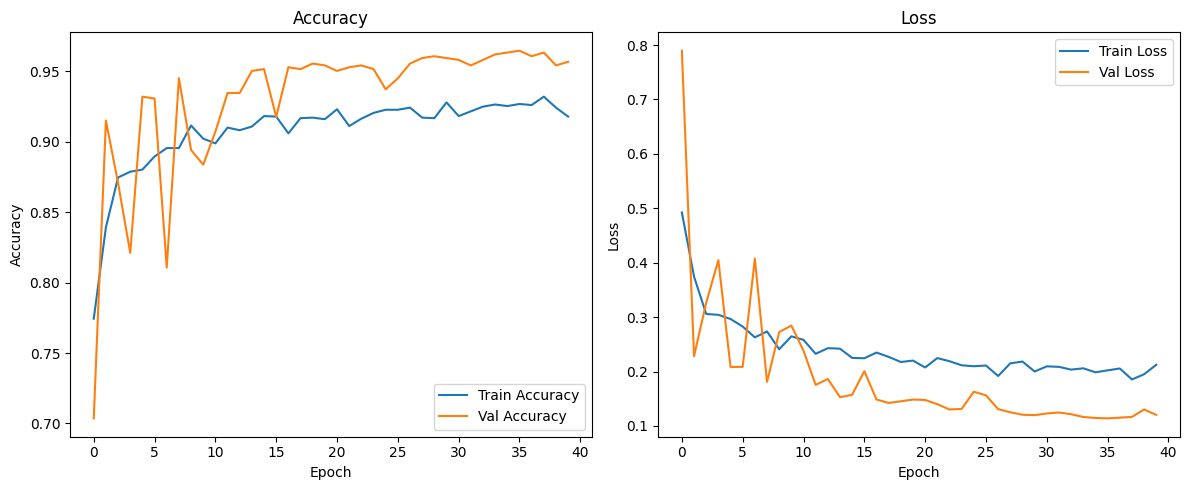

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.9403 - loss: 0.1428
Test Accuracy: 94.03%
Test Loss: 0.1428
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step


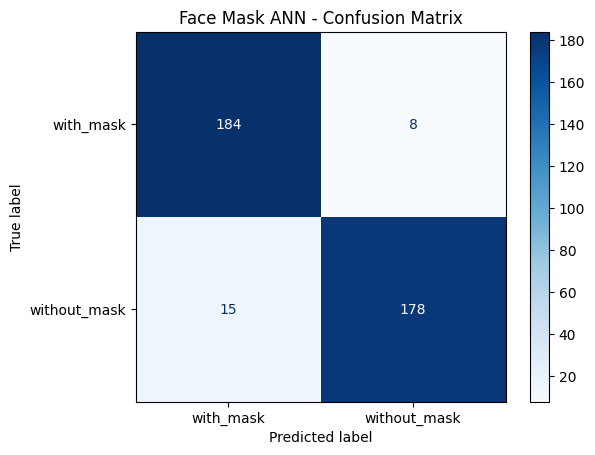

              precision    recall  f1-score   support

   with_mask       0.92      0.96      0.94       192
without_mask       0.96      0.92      0.94       193

    accuracy                           0.94       385
   macro avg       0.94      0.94      0.94       385
weighted avg       0.94      0.94      0.94       385



In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# 1) Graphs
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Val Accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

# 2) Test accuracy
test_loss, test_acc = model.evaluate(test_data)
print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# 3) Predictions
test_data.reset()
probs = model.predict(test_data)
y_pred = (probs >= 0.5).astype(int).flatten()
y_true = test_data.classes
class_names = list(test_data.class_indices.keys())

# 4) Confusion matrix
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
plt.title("Face Mask ANN - Confusion Matrix")
plt.show()

# 5) Classification report
print(classification_report(y_true, y_pred, target_names=class_names))

In [7]:
model.save("face_mask_ann_model.keras")
print("Model saved!")

Model saved!


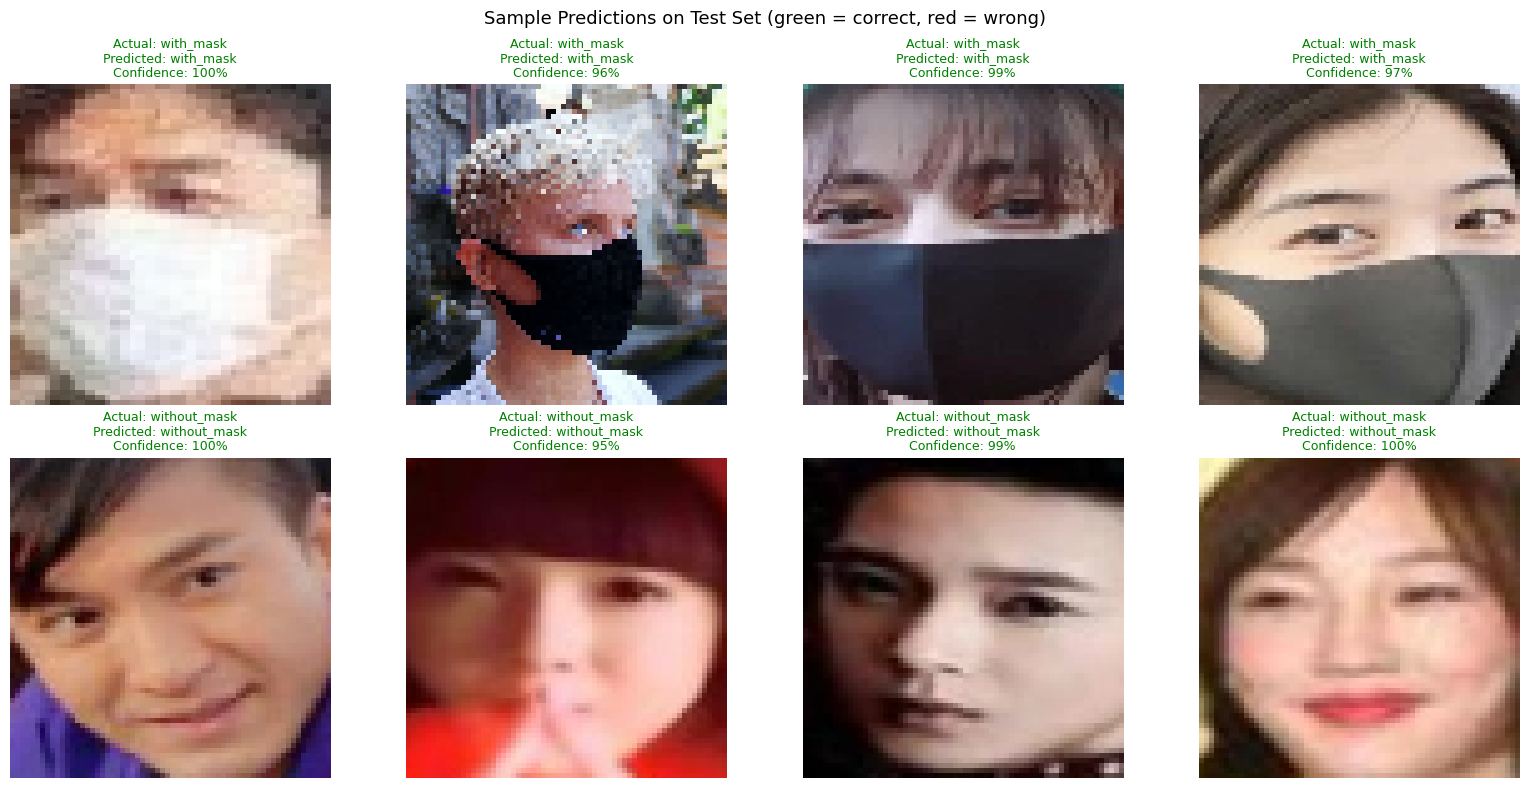

In [8]:
import os, random
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

# Map class index back to class name (0 -> with_mask, 1 -> without_mask)
idx_to_class = {v: k for k, v in train_data.class_indices.items()}
test_dir = "/content/output_dataset/test"

# Pick 4 random images from each class of the test set
samples = []
for cls in ["with_mask", "without_mask"]:
    files_in_class = os.listdir(f"{test_dir}/{cls}")
    for f in random.sample(files_in_class, 4):
        samples.append((f"{test_dir}/{cls}/{f}", cls))

# Predict and display
plt.figure(figsize=(16, 8))
for i, (path, true_cls) in enumerate(samples):
    img = image.load_img(path, target_size=(64, 64))
    arr = np.expand_dims(image.img_to_array(img) / 255.0, axis=0)

    prob = float(model.predict(arr, verbose=0)[0][0])
    pred_cls = idx_to_class[int(prob >= 0.5)]
    confidence = prob if prob >= 0.5 else 1 - prob

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.axis("off")
    color = "green" if pred_cls == true_cls else "red"
    plt.title(
        f"Actual: {true_cls}\nPredicted: {pred_cls}\nConfidence: {confidence*100:.0f}%",
        color=color, fontsize=9
    )

plt.suptitle("Sample Predictions on Test Set (green = correct, red = wrong)", fontsize=13)
plt.tight_layout()
plt.show()

In [10]:
from google.colab import files

model.save("face_mask_ann_v2.keras")
model.summary()
files.download("face_mask_ann_v2.keras")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,145,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,565,189 (36.49 MB)

 Trainable params: 3,188,097 (12.16 MB)

 Non-trainable params: 896 (3.50 KB)

 Optimizer params: 6,376,196 (24.32 MB)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
from google.colab import files

model.save("face_mask_ann_light.keras", include_optimizer=False)
files.download("face_mask_ann_light.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>